# BMI 500 - Homework 7

HW 1: SIR and SEIR Models

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update(
    {
        "font.size": 14,
        "axes.titlesize": 20,
        "axes.labelsize": 17,
        "axes.titlepad": 12,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 15,
        "figure.titlesize": 19,
        "lines.linewidth": 2.1,
        "figure.dpi": 110,
    }
)

## A. SIR model

In [2]:
def sir_derivatives(S, I, R, beta, gamma):
    new_infections = beta * S * I
    new_recoveries = gamma * I

    dS = -new_infections
    dI = new_infections - new_recoveries
    dR = new_recoveries

    return np.array([dS, dI, dR], dtype=float)


def simulate_sir(S0, I0, R0, beta, gamma, days, dt=0.1):
    steps = round(days / dt)
    t = np.linspace(0, days, steps + 1)
    states = np.zeros((steps + 1, 3))
    states[0] = [S0, I0, R0]

    for k in range(steps):
        S, I, R = states[k]
        change = sir_derivatives(S, I, R, beta, gamma)
        states[k + 1] = states[k] + dt * change

    return t, states

## B. SIR simulation

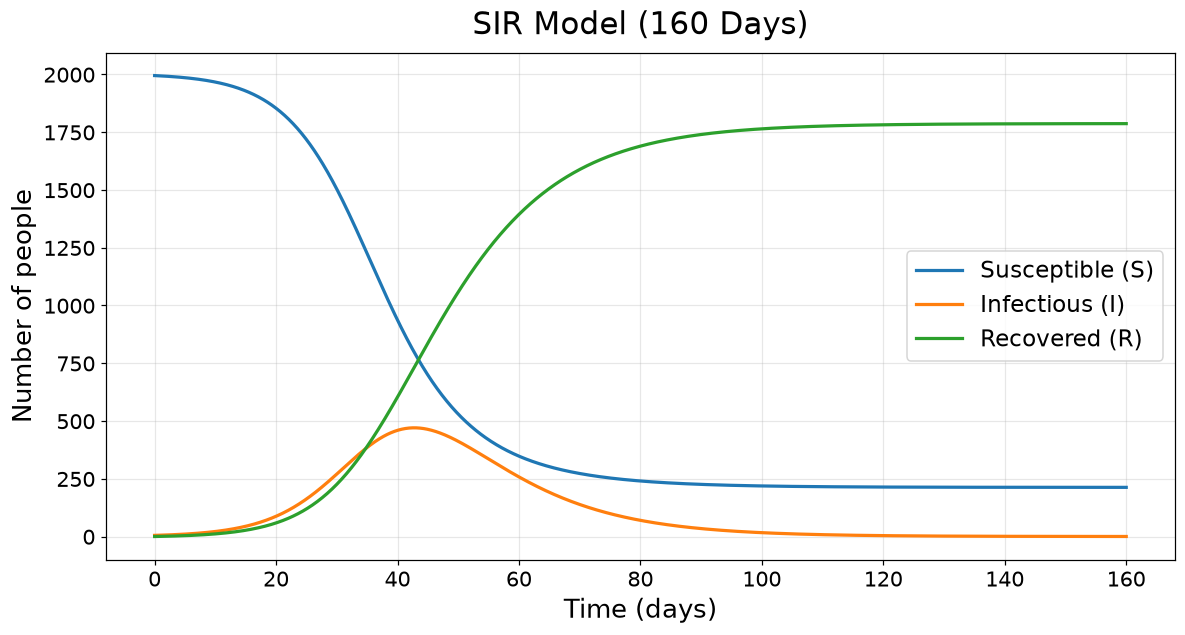

Day 160: S=212.79, I=0.20, R=1787.01


In [3]:
N = 2000
S0, I0, R0_initial = 1995, 5, 0
beta, gamma = 0.000125, 0.1

t, states = simulate_sir(S0, I0, R0_initial, beta, gamma, days=160, dt=0.1)

S = states[:, 0]
I = states[:, 1]
R = states[:, 2]

plt.figure(figsize=(11, 6))
plt.plot(t, S, label="Susceptible (S)")
plt.plot(t, I, label="Infectious (I)")
plt.plot(t, R, label="Recovered (R)")
plt.xlabel("Time (days)")
plt.ylabel("Number of people")
plt.title("SIR Model (160 Days)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Day 160: S={S[-1]:.2f}, I={I[-1]:.2f}, R={R[-1]:.2f}")

## C. SIR analysis

### (i) Infection peak

In [4]:
peak_idx = np.argmax(I)
peak_day = t[peak_idx]
peak_infected = I[peak_idx]
S_at_peak = S[peak_idx]

print(f"Peak day: {peak_day:.1f}")
print(f"Peak infectious: {peak_infected:.2f}")
print(f"S at peak: {S_at_peak:.2f}")
print(f"New infections/day: {beta * S_at_peak * peak_infected:.3f}")
print(f"Recoveries/day: {gamma * peak_infected:.3f}")

Peak day: 42.7
Peak infectious: 470.46
S at peak: 799.88
New infections/day: 47.039
Recoveries/day: 47.046


The peak is 470.46 people on day 42.7, earlier and lower than my hypothesis (day 50, about 536 people). I used 5-day Euler steps for the estimate, which likely explains most of the difference.

At the peak, new infections and recoveries are roughly equal. Setting $\beta SI=\gamma I$ gives $S=\gamma/\beta=800$. The simulation gives $S\approx799.88$.

### (ii) Basic reproduction number

In [5]:
R0_sir = beta * N / gamma
R_eff_start = beta * S[0] / gamma
R_eff_peak = beta * S[peak_idx] / gamma

print(f"SIR R0: {R0_sir:.3f}")
print(f"Initial R_eff: {R_eff_start:.3f}")
print(f"R_eff at peak: {R_eff_peak:.3f}")

SIR R0: 2.500
Initial R_eff: 2.494
R_eff at peak: 1.000


$R_0=\beta N/\gamma=2.5$. With a fully susceptible population, each infectious person would cause about 2.5 new infections on average. The outbreak can grow because $R_0>1$.

As $S$ falls, $R_{\mathrm{eff}}=\beta S/\gamma$ falls too. Once it is below 1, $I$ starts declining. Reducing transmission or shortening the infectious period would help control the outbreak.

### (iii) Epidemic dynamics

In [6]:
never_infected = S[-1]
ever_infected = N - S[-1]
new_during_simulation = S[0] - S[-1]

print(f"Never infected by day 160: {never_infected:.2f}")
print(f"Ever infected: {ever_infected:.2f}")
print(f"New infections after day 0: {new_during_simulation:.2f}")
print(f"I at day 160: {I[-1]:.2f}")
print(f"R at day 160: {R[-1]:.2f}")

Never infected by day 160: 212.79
Ever infected: 1787.21
New infections after day 0: 1782.21
I at day 160: 0.20
R at day 160: 1787.01


$S$ falls as people get infected. $I$ rises, peaks, then declines, while $R$ keeps increasing. By day 160, about 213 people have never been infected. Around 1,787 have recovered, and only 0.20 are still infectious. With no new susceptible people, the outbreak eventually fades out.

## D. SEIR with births and deaths

### (i) Implementation

In [7]:
def seir_derivatives(S, E, I, R, beta, gamma, sigma, mu, N):
    new_infections = beta * S * I
    new_infectious = sigma * E
    new_recoveries = gamma * I
    births = mu * N

    dS = births - new_infections - mu * S
    dE = new_infections - new_infectious - mu * E
    dI = new_infectious - new_recoveries - mu * I
    dR = new_recoveries - mu * R

    return np.array([dS, dE, dI, dR], dtype=float)


def simulate_seir(S0, E0, I0, R0, beta, gamma, sigma, mu, days, dt=0.1):
    N = S0 + E0 + I0 + R0
    steps = round(days / dt)
    t = np.linspace(0, days, steps + 1)
    states = np.zeros((steps + 1, 4))
    states[0] = [S0, E0, I0, R0]

    for k in range(steps):
        S, E, I, R = states[k]
        change = seir_derivatives(S, E, I, R, beta, gamma, sigma, mu, N)
        states[k + 1] = states[k] + dt * change

    return t, states

### (ii) Simulations: 365 and 1500 days

In [8]:
S0_d, E0_d, I0_d, R0_d = 1980, 15, 5, 0
beta_d, gamma_d = 0.000125, 0.1
sigma_d, mu_d = 0.25, 0.005

t365, states365 = simulate_seir(
    S0_d, E0_d, I0_d, R0_d, beta_d, gamma_d, sigma_d, mu_d, 365, dt=0.1
)
t1500, states1500 = simulate_seir(
    S0_d, E0_d, I0_d, R0_d, beta_d, gamma_d, sigma_d, mu_d, 1500, dt=0.1
)

for day, state in [(365, states365[-1]), (1500, states1500[-1])]:
    print(
        f"Day {day}: "
        + ", ".join(f"{name}={value:.2f}" for name, value in zip("SEIR", state))
    )

Day 365: S=829.84, E=35.03, I=84.70, R=1050.42
Day 1500: S=856.92, E=22.45, I=53.44, R=1067.20


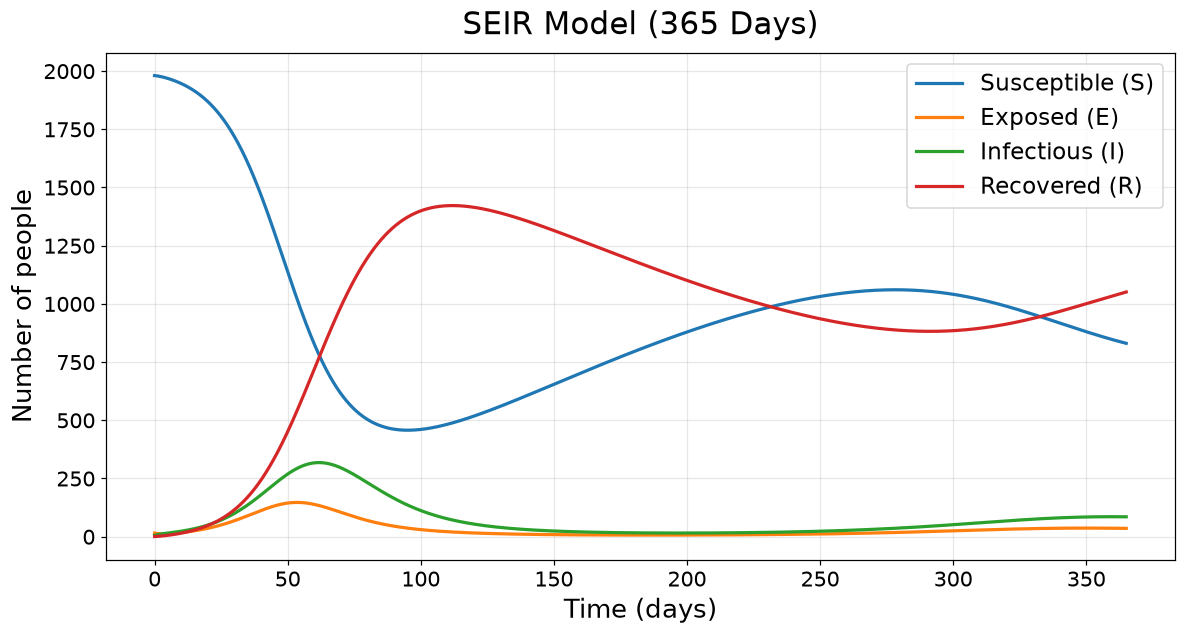

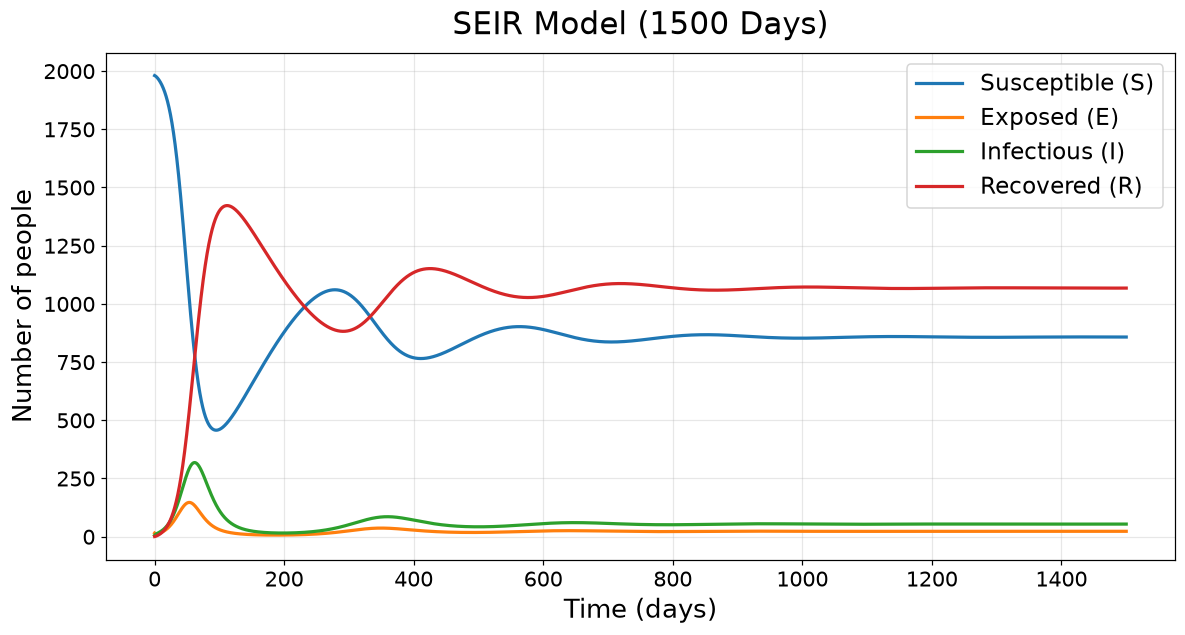

In [9]:
for time, data, days in [(t365, states365, 365), (t1500, states1500, 1500)]:
    plt.figure(figsize=(11, 6))
    plt.plot(time, data[:, 0], label="Susceptible (S)")
    plt.plot(time, data[:, 1], label="Exposed (E)")
    plt.plot(time, data[:, 2], label="Infectious (I)")
    plt.plot(time, data[:, 3], label="Recovered (R)")
    plt.xlabel("Time (days)")
    plt.ylabel("Number of people")
    plt.title(f"SEIR Model ({days} Days)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### (iii) Epidemic waves

Wave 1: day 61.7, I = 317.60
Wave 2: day 359.4, I = 85.09
Wave 3: day 648.0, I = 59.66
Wave 4: day 937.8, I = 54.76
Wave 5: day 1227.9, I = 53.68


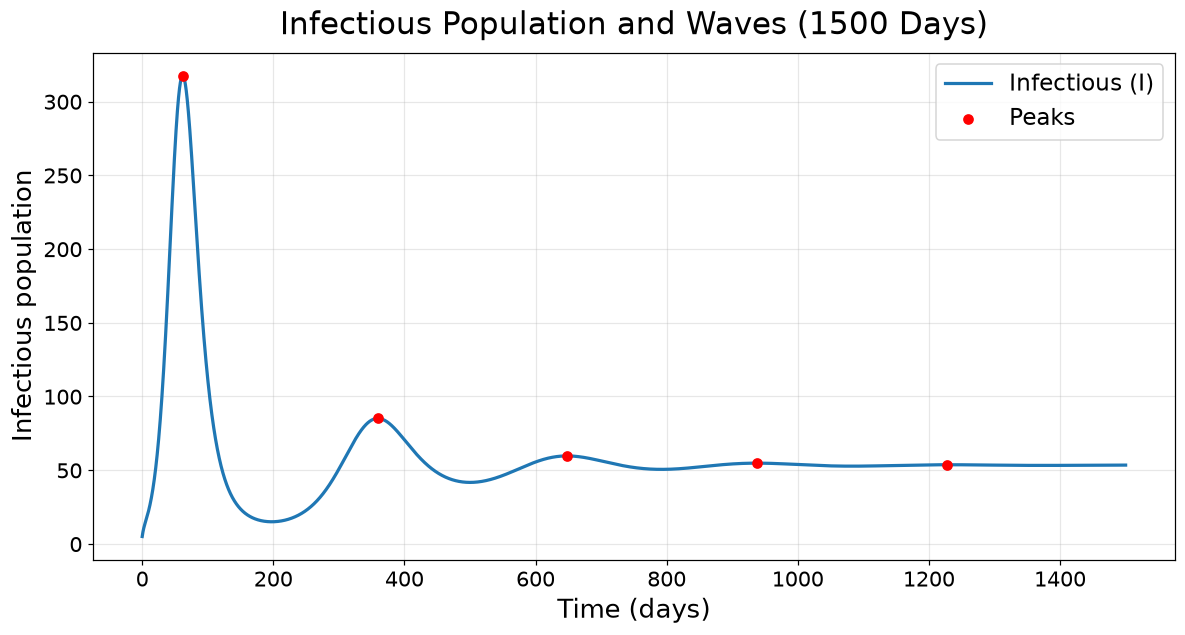

In [10]:
I1500 = states1500[:, 2]

peak_indices = []

for k in range(1, len(I1500) - 1):
    if I1500[k] > I1500[k - 1] and I1500[k] >= I1500[k + 1]:
        peak_indices.append(k)

for number, idx in enumerate(peak_indices, start=1):
    print(f"Wave {number}: day {t1500[idx]:.1f}, I = {I1500[idx]:.2f}")

plt.figure(figsize=(11, 6))
plt.plot(t1500, I1500, label="Infectious (I)")
plt.scatter(
    t1500[peak_indices], I1500[peak_indices], color="red", label="Peaks", zorder=3
)
plt.xlabel("Time (days)")
plt.ylabel("Infectious population")
plt.title("Infectious Population and Waves (1500 Days)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

I found five peaks (day, number infected): (61.7, 317.60), (359.4, 85.09), (648.0, 59.66), (937.8, 54.76), and (1227.9, 53.68). The peaks get smaller, and the infectious population eventually settles near 53, matching my hypothesis.

### (iv) Basic reproduction number and long-term S

In [11]:
R0_sir = beta_d * N / gamma_d
R0_seir = beta_d * N * sigma_d / ((sigma_d + mu_d) * (gamma_d + mu_d))

S_equilibrium = N / R0_seir
S_final = states1500[-1, 0]

print(f"SIR R0: {R0_sir:.3f}")
print(f"SEIR R0: {R0_seir:.3f}")
print(f"N / SEIR R0: {S_equilibrium:.2f}")
print(f"S at day 1500: {S_final:.2f}")
print(f"Difference: {abs(S_final - S_equilibrium):.4f}")

SIR R0: 2.500
SEIR R0: 2.334
N / SEIR R0: 856.80
S at day 1500: 856.92
Difference: 0.1235


For SEIR, $R_0=\frac{\beta N\sigma}{(\sigma+\mu)(\gamma+\mu)}\approx2.334$, compared with 2.5 for SIR. Death can prevent exposed people from reaching $I$ and can shorten the infectious period.

At the endemic equilibrium, $S^*=N/R_0\approx856.80$. The simulated value at day 1500 is 856.92, very close to equilibrium.

### (v) Changes with a realistic human lifespan

The exposed group delays infectiousness, which affects the timing of infection waves.

The birth/death rate is relatively high, with a mean lifespan of only 200 days. This replenishes the susceptible population quickly and allows repeated waves. With a realistic human lifespan, the birth/death rate would be much lower, so later waves would likely appear more slowly or be less visible within 1500 days.

## E. Sensitivity analysis

I ran 25 parameter combinations over 365 days. I calculated cumulative new infections by adding $\beta SI\,\Delta t$ at each step, since births and deaths also change $S$.


### (i) Parameter runs

In [12]:
beta_values = np.linspace(0.00005, 0.00025, 5)
gamma_values = np.linspace(0.05, 0.25, 5)
dt = 0.1

peak_rows = []
total_rows = []

for gamma_value in gamma_values:
    peak_row = []
    total_row = []

    for beta_value in beta_values:
        t_run, states_run = simulate_seir(
            S0_d, E0_d, I0_d, R0_d, beta_value, gamma_value, sigma_d, mu_d, 365, dt=dt
        )
        S_run = states_run[:, 0]
        I_run = states_run[:, 2]

        peak_row.append(np.max(I_run))
        total_row.append(np.sum(beta_value * S_run[:-1] * I_run[:-1] * dt))

    peak_rows.append(peak_row)
    total_rows.append(total_row)

peak_results = np.array(peak_rows)
total_results = np.array(total_rows)

print("Peak infectious:")
print(np.round(peak_results, 1))
print("\nTotal new infections:")
print(np.round(total_results, 1))

Peak infectious:
[[ 230.9  634.2  840.8  961.8 1039.9]
 [  13.3  207.8  408.9  546.9  644. ]
 [  10.5   43.4  184.9  308.8  404.8]
 [   9.1   10.5   69.8  165.8  250.9]
 [   8.1    8.8   18.8   80.9  150.2]]

Total new infections:
[[2280.5 3859.  4406.2 4688.2 4864.3]
 [ 171.7 2318.9 3559.2 3972.6 4285.7]
 [  33.1 1199.2 2462.  3387.8 3701.8]
 [  18.   209.2 1540.2 2627.4 3272.1]
 [  12.3   61.   825.8 1741.1 2729.8]]


### (ii) Contour plots

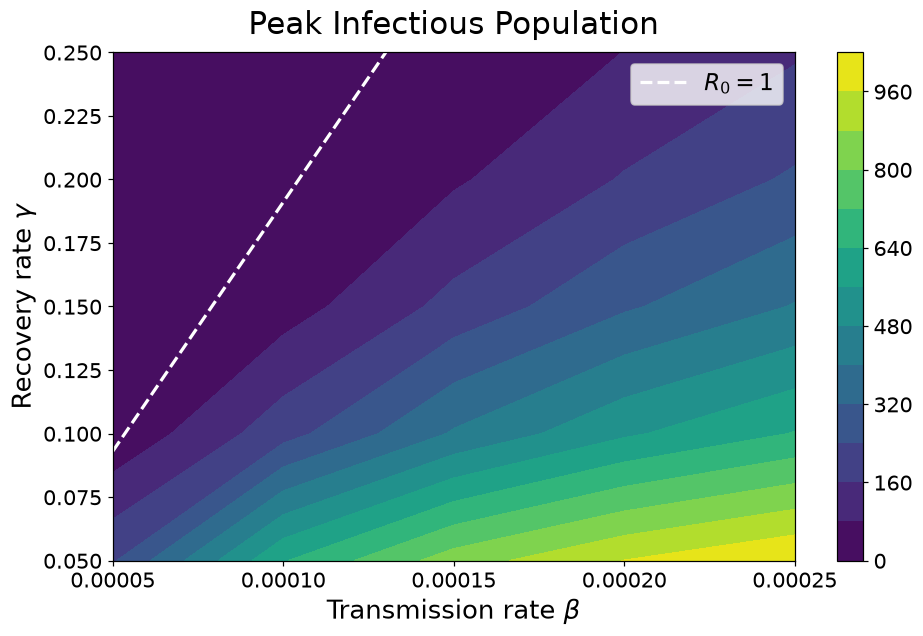

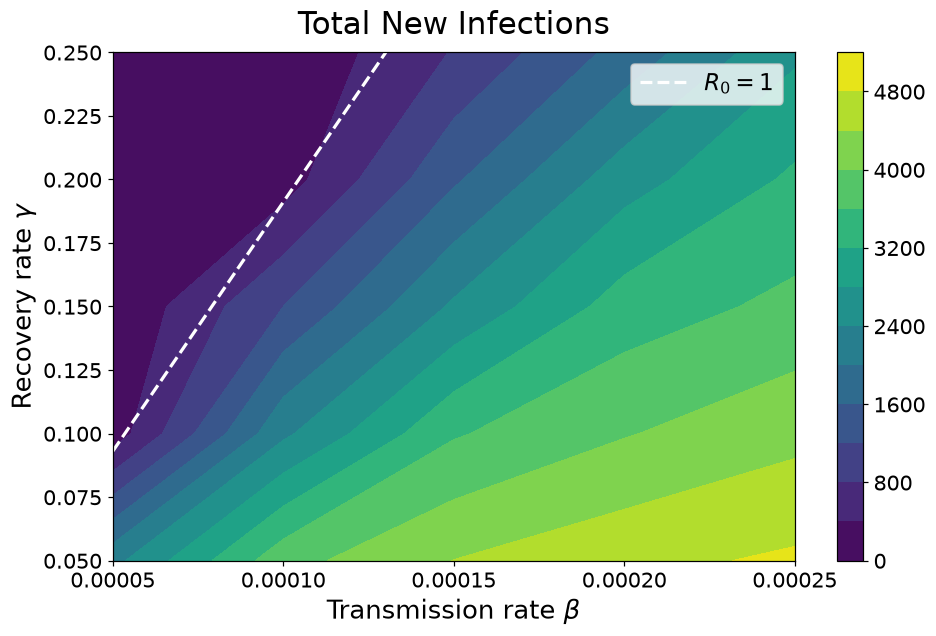

In [13]:
beta_line = np.linspace(beta_values[0], beta_values[-1], 100)
gamma_line = beta_line * N * sigma_d / (sigma_d + mu_d) - mu_d

for values, title in [
    (peak_results, "Peak Infectious Population"),
    (total_results, "Total New Infections"),
]:
    plt.figure(figsize=(10, 6))

    plt.contourf(beta_values, gamma_values, values, levels=12)
    plt.colorbar()

    plt.plot(beta_line, gamma_line, "w--", label=r"$R_0 = 1$")

    plt.xlim(beta_values[0], beta_values[-1])
    plt.ylim(gamma_values[0], gamma_values[-1])

    plt.xticks(beta_values, [f"{x:.5f}" for x in beta_values])

    plt.xlabel(r"Transmission rate $\beta$")
    plt.ylabel(r"Recovery rate $\gamma$")
    plt.title(title)
    plt.legend()

    plt.show()

The dashed line marks $R_0=1$, using $\gamma=\frac{\beta N\sigma}{\sigma+\mu}-\mu$. Above it $R_0<1$, and below it $R_0>1$.

### (iii) Public health implications

In [14]:
# Compare the full range of each parameter while holding the other at its midpoint
beta_peak_change = peak_results[2, -1] - peak_results[2, 0]
gamma_peak_change = peak_results[0, 2] - peak_results[-1, 2]

beta_total_change = total_results[2, -1] - total_results[2, 0]
gamma_total_change = total_results[0, 2] - total_results[-1, 2]

print(f"Peak change from beta: {beta_peak_change:.2f}")
print(f"Peak change from gamma: {gamma_peak_change:.2f}")
print(f"Total new infections change from beta: {beta_total_change:.2f}")
print(f"Total new infections change from gamma: {gamma_total_change:.2f}")

Peak change from beta: 394.25
Peak change from gamma: 822.00
Total new infections change from beta: 3668.69
Total new infections change from gamma: 3580.35


Higher $\beta$ gives larger peaks and more new infections, while higher $\gamma$ reduces both. Holding the other parameter at its midpoint, varying $\beta$ changes the peak by about 394 people, compared with 822 for $\gamma$. So $\gamma$ had a larger effect on the peak in this comparison, contrary to my hypothesis. For cumulative infections, the changes are about 3,669 and 3,580, respectively.

Social distancing can reduce $\beta$. Treatments that shorten the infectious period can increase $\gamma$. Both would help reduce transmission. The relative effect depends on the outcome and parameter range.